In [7]:
from optimizers import pairwise_bo, mixed_bo
import numpy as np
from itertools import combinations
from botorch.acquisition.preference import AnalyticExpectedUtilityOfBestOption
import torch
from botorch.models import SingleTaskGP
from botorch.models.pairwise_gp import PairwiseGP, PairwiseLaplaceMarginalLogLikelihood
from botorch.acquisition.monte_carlo import qNoisyExpectedImprovement
from botorch.fit import fit_gpytorch_model
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.optim import optimize_acqf
import warnings
# suppress warnings from potential numerical issues
warnings.filterwarnings("ignore")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device: ', device)

# data generating helper functions
def utility(X):
    """ Given X, output corresponding utility (i.e., the latent function)
    """
    # y is weighted sum of X, with weight sqrt(i) imposed on dimension i
    weighted_X = X * torch.sqrt(torch.arange(X.size(-1), dtype=torch.float) + 1)
    y = torch.sum(weighted_X, dim=-1)
    return y


def generate_data(n, dim=2):
    """ Generate data X and y """
    # X is randomly sampled from dim-dimentional unit cube
    # we recommend using double as opposed to float tensor here for
    # better numerical stability
    X = torch.rand(n, dim, dtype=torch.float64)
    y = utility(X)
    return X, y

def generate_comparisons(y, n_comp, noise=0.1, replace=False):
    """  Create pairwise comparisons with noise """
    # generate all possible pairs of elements in y
    all_pairs = np.array(list(combinations(range(y.shape[0]), 2)))
    # randomly select n_comp pairs from all_pairs
    comp_pairs = all_pairs[np.random.choice(range(len(all_pairs)), n_comp, replace=replace)]
    # add gaussian noise to the latent y values
    c0 = y.to('cpu')[comp_pairs[:, 0]] + np.random.standard_normal(len(comp_pairs)) * noise
    c1 = y.to('cpu')[comp_pairs[:, 1]] + np.random.standard_normal(len(comp_pairs)) * noise
    reverse_comp = (c0 < c1).numpy()
    comp_pairs[reverse_comp, :] = np.flip(comp_pairs[reverse_comp, :], 1)
    comp_pairs = torch.tensor(comp_pairs).long()

    return comp_pairs

def make_new_data(X, next_X, comps, q_comp):
    """Given X and next_X,
    generate q_comp new comparisons between next_X
    and return the concatenated X and comparisons
    """
    # next_X is float by default; cast it to the dtype of X (i.e., double)
    next_X = next_X.to(X)
    next_y = utility(next_X)
    next_comps = generate_comparisons(next_y, n_comp=q_comp, noise=noise)
    comps = torch.cat([comps, next_comps + X.shape[-2]])
    X = torch.cat([X, next_X])
    return X, comps

def init_and_fit_model(X, comp, state_dict=None):
    """Model fitting helper function"""
    model = PairwiseGP(X, comp)
    mll = PairwiseLaplaceMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_model(mll)
    return mll, model


algos = ["EUBO", "rand", "listwise"]

NUM_TRIALS = 10
NUM_BATCHES = 20

dim = 5
NUM_RESTARTS = 3
RAW_SAMPLES = 256
q = 2  # number of points per query
q_comp = 1  # number of comparisons per query
noise = 0.1

# initial evals
best_vals = {}  # best observed values
for algo in algos:
    best_vals[algo] = []

# average over multiple trials
for i in range(NUM_TRIALS):
    torch.manual_seed(i)
    np.random.seed(i)
    data = {}
    models = {}

    # Create initial data
    init_X, init_y = generate_data(q, dim=dim)
    comparisons = generate_comparisons(init_y, q_comp, noise=noise)
    test_X, test_y = generate_data(1000, dim=dim)
    # X are within the unit cube
    bounds = torch.stack([torch.zeros(dim), torch.ones(dim)])

    for algo in algos:
        best_vals[algo].append([])
        data[algo] = (init_X, comparisons)
        _, models[algo] = init_and_fit_model(init_X, comparisons)
        model = models[algo]

        best_next_y = utility(init_X).max().item()
        best_vals[algo][-1].append(best_next_y)

    # we make additional NUM_BATCHES comparison queries after the initial observation
    for j in range(1, NUM_BATCHES + 1):
        for algo in algos:
            if algo == "EUBO":
                # create the acquisition function object
                acq_func = AnalyticExpectedUtilityOfBestOption(pref_model=model)
                # optimize and get new observation
                next_X, acq_val = optimize_acqf(
                    acq_function=acq_func,
                    bounds=bounds,
                    q=q,
                    num_restarts=NUM_RESTARTS,
                    raw_samples=RAW_SAMPLES,
                )
            elif algo == "listwise":
                y_utility = models[algo].utility.clone().detach().requires_grad_(True).reshape(-1, 1)
                utilityGP = SingleTaskGP(data[algo][0], y_utility)
                fit_gpytorch_model(ExactMarginalLogLikelihood(
                    utilityGP.likelihood, utilityGP))
                qNEI = qNoisyExpectedImprovement(utilityGP, data[algo][0])
                next_X, acq_val = optimize_acqf(
                    qNEI,
                    bounds=bounds,
                    q=2,
                    num_restarts=5,
                    raw_samples=20,
                )
            else:
                # randomly sample data
                next_X, _ = generate_data(q, dim=dim)

            # update data
            X, comps = data[algo]
            X, comps = make_new_data(X, next_X, comps, q_comp)
            data[algo] = (X, comps)

            # refit models
            model = models[algo]
            _, model = init_and_fit_model(X, comps, model.state_dict())
            models[algo] = model

            # record the best observed values so far
            max_val = utility(X).max().item()
            best_vals[algo][-1].append(max_val)

device:  cpu


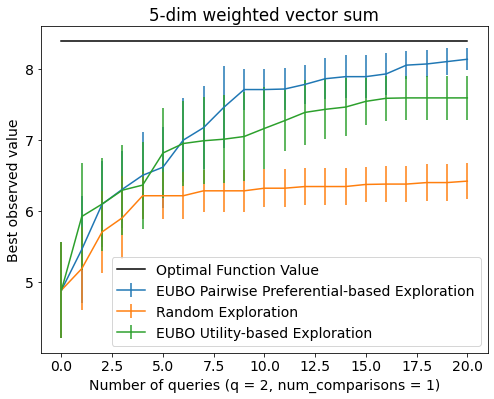

In [8]:
from matplotlib import pyplot as plt


%matplotlib inline

plt.rcParams.update({"font.size": 14})

algo_labels = {
    "rand": "Random Exploration",
    "EUBO": "EUBO Pairwise Preferential-based Exploration",
    "listwise": "EUBO Utility-based Exploration",
}


def ci(y):
    return 1.96 * y.std(axis=0) / np.sqrt(y.shape[0])


# the utility function is maximized at the full vector of 1
optimal_val = utility(torch.tensor([[1] * dim])).item()
iters = list(range(NUM_BATCHES + 1))

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
# plot the optimal value
ax.plot(iters, [optimal_val] * len(iters), label="Optimal Function Value", color="black", linewidth=1.5)

# plot the the best observed value from each algorithm
for algo in algos:
    ys = np.vstack(best_vals[algo])
    ax.errorbar(iters, ys.mean(axis=0), yerr=ci(ys), label=algo_labels[algo], linewidth=1.5)

ax.set(
    xlabel=f"Number of queries (q = {q}, num_comparisons = {q_comp})",
    ylabel="Best observed value",
    title=f"{dim}-dim weighted vector sum",
)
ax.legend(loc="best")
plt.savefig("pairwise.pdf")